# Previsão do overall - EA FC 27

A ideia aqui é ver se dá pra adivinhar o overall de um jogador só pelos seis atributos da carta (pace, shooting, passing, dribbling, defending e physicality).

Base: EA Sports FC 27 Player Ratings, do Kaggle.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('players.csv')
df.head()

,player_id,common_name,first_name,last_name,overall_rating,position,alternate_positions,club,league,nationality,...,defending_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,edition,snapshot_date
0,227203,Alexia Putellas,Alexia,Putellas Segura,91,CM,CAM ST,London City,Barclays WSL,Spain,...,60,82,64,15,17,11,15,10,fc27,2026-09-12
1,231747,NaN,Kylian,Mbappé,91,ST,LW,Real Madrid,LALIGA EA SPORTS,France,...,15,34,24,13,5,7,11,6,fc27,2026-09-12
2,239085,NaN,Erling,Haaland,91,ST,NaN,Manchester City,Premier League,Norway,...,42,47,33,7,14,13,11,7,fc27,2026-09-12
3,192119,NaN,Thibaut,Courtois,90,GK,NaN,Real Madrid,LALIGA EA SPORTS,Belgium,...,20,18,16,87,89,78,90,90,fc27,2026-09-12
4,202126,NaN,Harry,Kane,90,ST,NaN,FC Bayern München,Bundesliga,England,...,46,44,42,8,10,11,14,11,fc27,2026-09-12


### Olhando os dados

In [2]:
print(df.shape)
df['overall_rating'].describe()

(19789, 60)


count    19789.000000
mean        66.723281
std          6.959486
min         47.000000
25%         62.000000
50%         67.000000
75%         71.000000
max         91.000000
Name: overall_rating, dtype: float64

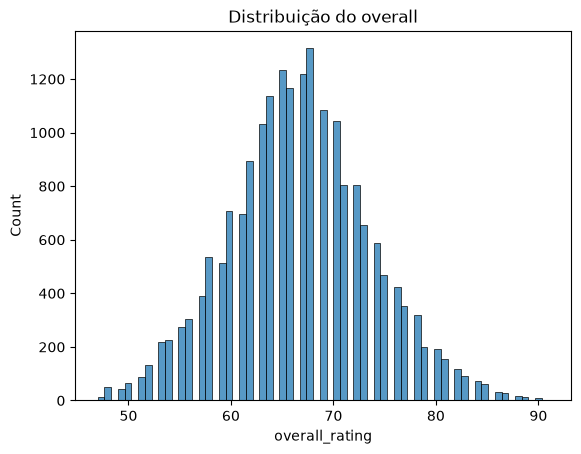

In [3]:
sns.histplot(df['overall_rating'])
plt.title('Distribuição do overall')
plt.show()

A maioria dos jogadores fica entre 62 e 71 de overall.

Vou tirar os goleiros, porque o overall deles vem de outros atributos (diving, reflexes...).

In [4]:
df_linha = df[df['position'] != 'GK']
len(df_linha)

17585

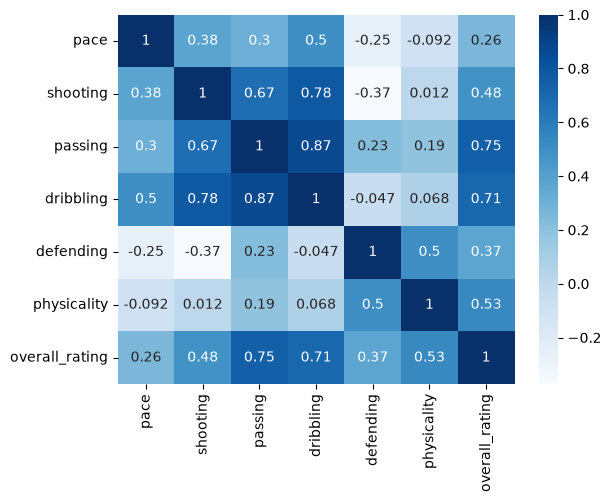

In [5]:
features = ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physicality']

sns.heatmap(df_linha[features + ['overall_rating']].corr(), annot=True, cmap='Blues')
plt.show()

Passing (0,75) e dribbling (0,71) são os que mais têm a ver com o overall. Pace (0,26) quase não influencia.

### Treino e teste

Dividi os jogadores em dois grupos:
- treino (80%): o modelo vê os atributos e o overall de verdade, pra aprender
- teste (20%): o modelo só vê os atributos e tem que chutar o overall

Depois comparo o chute com o overall real.

In [6]:
from sklearn.model_selection import train_test_split

X = df_linha[features]
y = df_linha['overall_rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Regressão Linear

In [7]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_train, y_train)
previsto_regressao = modelo.predict(X_test).round()

Overall real x previsto pela regressão (diferença = previsto - real):

In [8]:
teste = df_linha.loc[X_test.index]

comparacao = pd.DataFrame({
    'jogador': teste['first_name'] + ' ' + teste['last_name'],
    'posicao': teste['position'],
    'real': y_test,
    'previsto': previsto_regressao,
})
comparacao['diferenca'] = comparacao['previsto'] - comparacao['real']

comparacao.sort_values('real', ascending=False).head(10)

,jogador,posicao,real,previsto,diferenca
6,Rodrigo Hernández Cascante,CDM,90,83.0,-7.0
4,Harry Kane,ST,90,82.0,-8.0
9,Michael Olise,RM,90,82.0,-8.0
21,Ewa Pajor,ST,89,78.0,-11.0
15,Bruno Miguel Borges Fernandes,CAM,89,83.0,-6.0
31,Raphael Dias Belloli,LW,88,82.0,-6.0
34,María Pilar León Cebrián,CB,88,83.0,-5.0
39,Klara Bühl,LM,88,80.0,-8.0
52,Irene Paredes Hernández,CB,87,78.0,-9.0
56,Rose Lavelle,CAM,87,80.0,-7.0


In [9]:
print('Em média a regressão errou', comparacao['diferenca'].abs().mean().round(1), 'pontos')

Em média a regressão errou 2.6 pontos


A regressão chega perto, mas em alguns jogadores erra feio. Acho que é porque ela usa a mesma conta pra todas as posições, e defending pesa muito pra zagueiro e quase nada pra atacante.

### Random Forest

Testei outro modelo pra ver se melhorava.

In [10]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
comparacao['previsto_rf'] = rf.predict(X_test).round()
comparacao['diferenca_rf'] = comparacao['previsto_rf'] - comparacao['real']

comparacao.sort_values('real', ascending=False).head(10)

,jogador,posicao,real,previsto,diferenca,previsto_rf,diferenca_rf
6,Rodrigo Hernández Cascante,CDM,90,83.0,-7.0,87.0,-3.0
4,Harry Kane,ST,90,82.0,-8.0,85.0,-5.0
9,Michael Olise,RM,90,82.0,-8.0,89.0,-1.0
21,Ewa Pajor,ST,89,78.0,-11.0,87.0,-2.0
15,Bruno Miguel Borges Fernandes,CAM,89,83.0,-6.0,85.0,-4.0
31,Raphael Dias Belloli,LW,88,82.0,-6.0,87.0,-1.0
34,María Pilar León Cebrián,CB,88,83.0,-5.0,85.0,-3.0
39,Klara Bühl,LM,88,80.0,-8.0,87.0,-1.0
52,Irene Paredes Hernández,CB,87,78.0,-9.0,87.0,0.0
56,Rose Lavelle,CAM,87,80.0,-7.0,85.0,-2.0


Reparei que nos melhores jogadores os dois modelos chutaram pra baixo, mas a random forest chegou bem mais perto. O Michael Olise, por exemplo, tem 90: a regressão previu 82 e a random forest 89.

In [11]:
print('Em média a regressão errou', comparacao['diferenca'].abs().mean().round(1), 'pontos')
print('Em média a random forest errou', comparacao['diferenca_rf'].abs().mean().round(1), 'pontos')

Em média a regressão errou 2.6 pontos
Em média a random forest errou 0.9 pontos


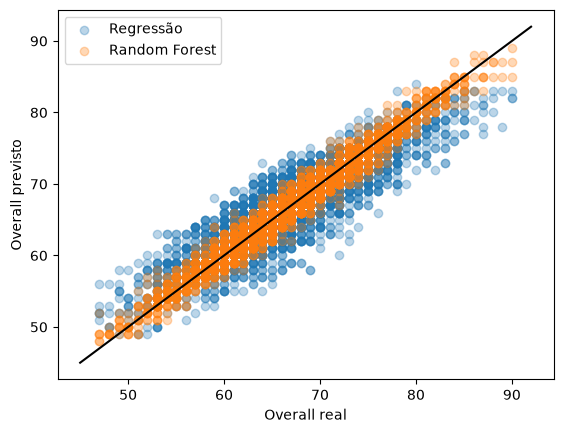

In [12]:
plt.scatter(comparacao['real'], comparacao['previsto'], alpha=0.3, label='Regressão')
plt.scatter(comparacao['real'], comparacao['previsto_rf'], alpha=0.3, label='Random Forest')
plt.plot([45, 92], [45, 92], color='black')
plt.xlabel('Overall real')
plt.ylabel('Overall previsto')
plt.legend()
plt.show()

A linha preta é onde o previsto bate com o real. Quanto mais perto dela, melhor, e os pontos da random forest ficam bem mais colados.

### Conclusão

A random forest foi bem melhor que a regressão linear. Ela erra menos de 1 ponto em média, enquanto a regressão erra uns 2 ou 3. Meu palpite é que a random forest consegue montar regras diferentes pra cada tipo de jogador, e a regressão usa uma fórmula só pra todo mundo.

O ponto fraco é que os dois modelos erram mais nos jogadores com overall muito alto ou muito baixo.